# Joint Perturb-seq Perturbation Analysis

Jin et al. 2020 (*Nature Neuroscience*) used Perturb-seq to map the transcriptional
effects of neuronal gene knockdowns in excitatory neurons.

This tutorial uses a subset of the data to demonstrate the full **causarray** workflow:
- **29 perturbations**, ~2 900 cells, ~3 200 genes
- Data downloaded from the [Broad Single Cell Portal](https://singlecell.broadinstitute.org/single_cell/study/SCP1184)

**Pipeline overview**
```
perturbseq-exneu.h5ad
      |
      v  prep_causarray_data
   Y, A, X
      |
      v  estimate_r  →  select r (JIC criterion)
      |
      v  fit_gcate   →  estimate latent confounders U
      |
      v  LFC         →  doubly-robust log-fold changes
```

In [7]:
import os 
import sys
sys.path.append('../../..')

import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests
import seaborn as sns
import matplotlib.pyplot as plt

# import scanpy as sc
import h5py

from causarray import (
    prep_causarray_data, fit_gcate, LFC, estimate_propensity_scores,
    summarize_propensity_scores, plot_propensity_scores, refit_propensity_scores,
    summarize_treatment_associations, plot_treatment_associations,
)


# Paths for jin-2020 dataset
PATHS = {'data_dir':  '/Users/catherinewang/Documents/School/genData/jin/',
         'save_dir': '/Users/catherinewang/Documents/School/proximal-scCRISPR-github/jin-2020/saves',
         'util_dir': '/Users/catherinewang/Documents/School/proximal-scCRISPR-github/utils'}
PATHS['save_dir'] = PATHS['save_dir'] + '_exneu_unpert'

The data can be downloaded from the Broad Single Cell Portal
(https://singlecell.broadinstitute.org/single_cell/study/SCP1184).
Here we use a pre-processed subset saved as `perturbseq-exneu.h5ad`.

In [3]:
# adata = sc.read_h5ad(PATHS['save_dir'] + 'perturbseq-exneu.h5ad')
# # adata = sc.read_h5ad('../../../../genData/jin/causarrayexampledata/perturbseq-exneu.h5ad')
# adata

For running causarray, we require the following inputs:

- `Y`: the cell-by-gene gene expression matrix.
- `A`: the cell-by-condition binary matrix of the perturbation/treatment conditions.
- `X, X_A`: (optional) the cell-by-covariate matrix of the covariates of interest for outcome and propensity models.

Here, `Y` and `A` can be dataframes.

In [4]:
# Y = pd.DataFrame(adata.X.copy(), columns=adata.var.index)
# A = pd.get_dummies(adata.obs['Perturbation'], columns=['Perturbation'], drop_first=False).drop(columns=['GFP'])

# Y, A, X, X_A = prep_causarray_data(Y, A)
# a = A.shape[1]
# a

## Load data from GEO processed

This will have more outcome genes, including the perturbation targets.

For running causarray, we require the following inputs:

- `Y`: the cell-by-gene gene expression matrix.
- `A`: the cell-by-condition binary matrix of the perturbation/treatment conditions.
- `X, X_A`: (optional) the cell-by-covariate matrix of the covariates of interest for outcome and propensity models.

Here, `Y` and `A` can be dataframes.

In [13]:
# should be saved as h5 file from R as
#           counts/
#           counts/counts
#           counts/row_genenames
#           counts/col_cellnames

# Open the H5 file in read mode
with h5py.File(PATHS['save_dir'] + '/jin_exneu.h5', 'r') as file:
    # a_group_key = list(file.keys())[0]
    # print(a_group_key)
    # Getting the data
    # data = list(file[a_group_key])
    # data = file[a_group_key][()]
    h5group = file['counts']

    counts = h5group['counts'][()] 
    count_row_genenames =  h5group['row_genenames'][()]
    count_col_cellnames =  h5group['col_cellnames'][()]

    h5group = file['grna']
    
    grna = h5group['grna'][()] 
    grna_row_grnanames =  h5group['row_grnanames'][()]
    grna_col_cellnames =  h5group['col_cellnames'][()]



In [14]:
Y = pd.DataFrame(counts.T, 
                    index=[x.decode("utf-8") for x in count_col_cellnames], 
                    columns=[x.decode('utf-8') for x in count_row_genenames])

A = pd.DataFrame(grna.T, 
                    index=[x.decode("utf-8") for x in grna_col_cellnames], 
                    columns=[x.decode('utf-8') for x in grna_row_grnanames])
A = A.drop(columns=['UnPert']) # remove 'GFP' col
# A = pd.read_csv(PATHS['save_dir'] + 'grna.csv', index_col=0)
# A = A.loc[Y.index, :] # reorder so cells are in same order
# A = A.drop(columns=['GFP']) # remove 'GFP' col

In [22]:
Y, A, X, X_A = prep_causarray_data(Y, A)
a = A.shape[1]


### Number of latent factors

We estimate the number of unmeasured confounders *r* using the JIC criterion: JIC fits
GCATE for each candidate *r* and scores the fit with a likelihood penalty, and we take the
*r* that minimises it.

JIC on its own can keep favouring larger *r*, but *r* is a count of parameters and must
stay small relative to the sample size. With about 100 treated cells per perturbation,
fitting tens of factors would overfit, so we search only up to `r = 20` and rely on
regularisation (the propensity section below) rather than on adding more factors. A useful
rule of thumb is to keep *r* well under the number of cases — for example `r ≈ 5` when
`n ≈ 30`. Here the minimum sits at `r = 10`, which is already generous for this sample.

In [24]:
from causarray import estimate_r, plot_r
# load in if previously run and saved, else run
if('perturbseq-r.csv' in os.listdir(PATHS['save_dir'] + '/causarray/')): 
    df_r = pd.read_csv(PATHS['save_dir'] + '/causarray/' + 'perturbseq-r.csv')
else: 
    df_r = estimate_r(Y, X, A, np.concat([[1, 2, 3], np.arange(5,55,5)])) # 350 mins on laptop- not sure if parallel worked
    df_r.to_csv(PATHS['save_dir'] + '/causarray/' + 'perturbseq-r.csv', index=False)

'Fitting nb GLM with offset...'
'Fitting nb GLM with offset...'
'Fitting nb GLM with offset...'
'Fitting GCATE (step 1)...'
'Fitting nb GLM with offset...'
'Fitting nb GLM with offset...'
'Fitting GCATE (step 1)...'
'Fitting nb GLM with offset...'
'Fitting nb GLM with offset...'
'Fitting GCATE (step 1)...'
'Fitting nb GLM with offset...'
'Fitting nb GLM with offset...'
'Fitting GCATE (step 1)...'
'Fitting nb GLM with offset...'
'Fitting nb GLM with offset...'
'Fitting GCATE (step 1)...'
'Fitting nb GLM with offset...'
'Fitting nb GLM with offset...'
'Fitting GCATE (step 1)...'
'Fitting nb GLM with offset...'
'Fitting nb GLM with offset...'
'Fitting GCATE (step 1)...'
'Fitting nb GLM with offset...'
'Fitting nb GLM with offset...'
'Fitting GCATE (step 1)...'
'Fitting nb GLM with offset...'
'Fitting nb GLM with offset...'
'Fitting GCATE (step 1)...'
'Fitting nb GLM with offset...'
'Fitting nb GLM with offset...'
'Fitting GCATE (step 1)...'
'Fitting nb GLM with offset...'
'Fitting nb GLM 

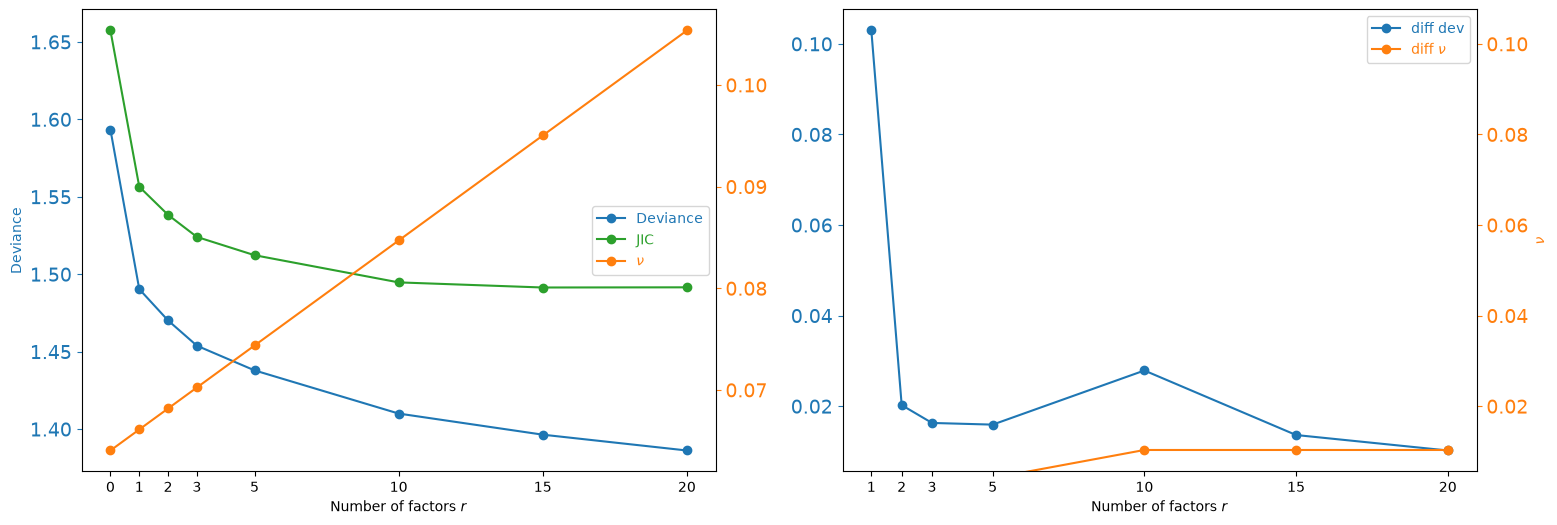

In [25]:
# ~100 treated cells per perturbation: cap the search well below the sample size
# and read the minimum from that range instead of chasing ever-larger r.
df_r = df_r[df_r['r'] <= 20]
fig = plot_r(df_r)

In [26]:
# from causarray import estimate_r, plot_r
# # df_r = estimate_r(Y, X, A, np.concat([[1, 2, 3], np.arange(5,55,5)]))
# # df_r.to_csv(PATHS['save_dir'] + '/causarray/perturbseq-r.csv', index=False)
# df_r = pd.read_csv(PATHS['save_dir'] + 'causarray/perturbseq-r.csv')
# # ~100 treated cells per perturbation: cap the search well below the sample size
# # and read the minimum from that range instead of chasing ever-larger r.
# df_r = df_r[df_r['r'] <= 20]
# fig = plot_r(df_r)

### Estimate unmeasured confounders

We run **GCATE** with the selected *r* to estimate latent factors that capture
unmeasured confounders (e.g. cell-cycle phase, technical variation).
The estimated factors are appended to the covariate matrix before calling `LFC`.

In [28]:
import pickle
r = 10 # CHANGE: we choose 10... could also just choose 5. Probably should try a few more values between 5-10
U_filename = f'U_r={r:}.csv'
res_2_filename = f'res_2_r={r:}.pkl'


# load in if previously run and saved, else run
if(U_filename in os.listdir(PATHS['save_dir'] + '/causarray/')): 
    # read U as
    U = pd.read_csv(PATHS['save_dir'] + '/causarray/' + U_filename)

    # load res_2 object as pickle
    # with open(PATHS['save_dir'] + '/causarray/' + res_2_filename, 'rb') as file:
    #     res_2 = pickle.load(file)
else: 
    
    res_1, res_2 = fit_gcate(Y, X, A, r, verbose=True,
        kwargs_es_1=dict(rel_tol=2e-4, max_iters=30),
        kwargs_es_2=dict(rel_tol=2e-4, max_iters=30),
    )
    U = res_2['U']
    print(f"\nStep 1  -- epochs: {res_1['n_iter']},  best NLL: {min(res_1['hist']):.6f}")
    print(f"Step 2  -- epochs: {res_2['n_iter']},  best NLL: {min(res_2['hist']):.6f}")

    # save U as csv
    pd.DataFrame(U).to_csv(PATHS['save_dir'] + '/causarray/' + U_filename, index=False)
    
    # save res_2 object as pickle
    # with open(PATHS['save_dir'] + '/causarray/' + res_2_filename, 'wb') as file:
    #     pickle.dump(res_2, file)

{'d': 31, 'n': 8215, 'p': 4017, 'r': 10}
'Estimating initial latent variables with GLMs...'
'Fitting nb GLM with offset...'


100%|██████████| 4017/4017 [00:20<00:00, 196.33it/s]


'Fitting GLM done.'
'Estimating initial coefficients with GLMs...'
'Fitting nb GLM with offset...'


100%|██████████| 4017/4017 [01:58<00:00, 33.96it/s]


'Fitting GLM done.'
{'kwargs_es': {'max_iters': 30,
               'patience': 5,
               'rel_tol': 0.0002,
               'tolerance': 0.0,
               'warmup': 0},
 'kwargs_glm': {'disp_glm': array([[1., 1., 1., ..., 1., 1., 1.]], shape=(1, 4017)),
                'family': 'nb',
                'size_factor': array([0.71953303, 0.83855047, 0.85908508, ..., 0.71008382, 0.72665003,
       0.86306085], shape=(8215,))},
 'kwargs_ls': {'C': 1000.0,
               'alpha': 0.1,
               'beta': 0.5,
               'max_iters': 20,
               'recheck_interval': 10,
               'sparsity_boost': 2.0,
               'sparsity_threshold': 0.5,
               'tol': 0.0001,
               'tol_cell': 0.0001,
               'tol_gene': 0.0001,
               'warmup_iters': 0}}
'Fitting GCATE (step 1)...'


 20%|██        | 6/30 [00:11<00:46,  1.92s/it, Early stopped. Best Epoch: 0. Best Metric: 1.716180.]


{'d': 31, 'n': 8215, 'p': 4017, 'r': 10}
{'kwargs_es': {'max_iters': 30,
               'patience': 5,
               'rel_tol': 0.0002,
               'tolerance': 0.0,
               'warmup': 0},
 'kwargs_glm': {'disp_glm': array([1., 1., 1., ..., 1., 1., 1.], shape=(4017,)),
                'family': 'nb',
                'size_factor': array([0.71953303, 0.83855047, 0.85908508, ..., 0.71008382, 0.72665003,
       0.86306085], shape=(8215,))},
 'kwargs_ls': {'C': 1000.0,
               'alpha': 0.1,
               'beta': 0.5,
               'max_iters': 20,
               'recheck_interval': 10,
               'sparsity_boost': 2.0,
               'sparsity_threshold': 0.5,
               'tol': 0.0001,
               'tol_cell': 0.0001,
               'tol_gene': 0.0001,
               'warmup_iters': 0}}
'Fitting GCATE (step 2)...'


 97%|█████████▋| 29/30 [00:51<00:01,  1.78s/it, Early stopped. Best Epoch: 23. Best Metric: 1.718025.]


Step 1  -- epochs: 6,  best NLL: 1.715914
Step 2  -- epochs: 29,  best NLL: 1.717730


In [29]:
# r = 10
# res_1, res_2 = fit_gcate(Y, X, A, r, verbose=True,
#     kwargs_es_1=dict(rel_tol=2e-4, max_iters=30),
#     kwargs_es_2=dict(rel_tol=2e-4, max_iters=30),
# )
# U = res_2['U']
# print(f"\nStep 1  -- epochs: {res_1['n_iter']},  best NLL: {min(res_1['hist']):.6f}")
# print(f"Step 2  -- epochs: {res_2['n_iter']},  best NLL: {min(res_2['hist']):.6f}")

### Estimate log-fold change based on counterfactuals

Next, we apply causarray to estimate the causal effects of perturbations on gene expression. Here the 106 GFP control cells and the perturbation groups (median 89 cells) are similar in size, so we use pooled variance to retain power in this relatively small comparison. This is a dataset-specific choice: unequal variance is preferable when the treated and control groups differ meaningfully in size or effective sample size, when outcome variability differs between the two groups, and for the Replogle and case-control tutorials.

In [33]:
df_res_filename     = 'LFC.csv'
estimation_filename = 'LFC_estimation.pkl'

gene_deviance = pd.read_csv(PATHS['save_dir'] + '/gene_dev.csv')
chosen_response_genes = gene_deviance.query('is_grna_target or importance_rank <= 1500') # desired, but errs? works but then errs, just load in next time

# gene_deviance_topnoTFonly = pd.read_csv(PATHS['save_dir'] + '/gene_deviance_topnoTFonly.csv')
# chosen_response_genes = gene_deviance_topnoTFonly.query('is_grna_target or importance_rank <= 1000')  # test w smaller set
# chosen_response_genes = gene_deviance_topnoTFonly.query('is_grna_target or importance_rank <= 1200')  # ok with 1200
# chosen_response_genes = gene_deviance_topnoTFonly.query('is_grna_target or importance_rank <= 1500') # desired, but errs? works but then errs, just load in next time


offsets = np.log(res_2['kwargs_glm']['size_factor']) # use the precomputed size factors

# load in if previously run and saved, else run
if((    df_res_filename in os.listdir(PATHS['save_dir'] + '/causarray/'))
   and 
   (estimation_filename in os.listdir(PATHS['save_dir'] + '/causarray/'))): 
    # load df_res as csv
    df_res = pd.read_csv(PATHS['save_dir'] + '/causarray/' + df_res_filename)

    # load estimation object as pickle
    # with open(PATHS['save_dir'] + '/causarray/' + estimation_filename, 'rb') as file:
    #     estimation = pickle.load(file)
else: 
    df_res, estimation = LFC(Y.loc[:, chosen_response_genes.loc[:, 'gene_name']],  
                             np.c_[X, U], A, np.c_[X_A, U], offset=offsets, usevar='unequal', verbose=True)

    # save U as csv
    df_res.to_csv(PATHS['save_dir'] + '/causarray/' + df_res_filename, index=False)
    
    # save res_2 object as pickle
    # with open(PATHS['save_dir'] + '/causarray/' + estimation_filename, 'wb') as file:
    #     pickle.dump(estimation, file)

'Estimating LFC...'
{'a': 30, 'd': 11, 'd_A': 12, 'estimands': 'LFC', 'n': 8215, 'p': 1532}
{'offset': array([-0.32915285, -0.1760805 , -0.15188731, ..., -0.34237226,
       -0.31931031, -0.14727008], shape=(8215,)),
 'random_state': 0,
 'verbose': True}
'Fit propensity score models...'
{'C': 1.0,
 'class_weight': 'balanced',
 'fit_intercept': False,
 'random_state': 0,
 'verbose': False}
'Fit outcome models...'
'Estimating dispersion parameter...'
'Fitting poisson GLM with offset...'
'Fitting nb GLM with offset...'


100%|██████████| 1532/1532 [00:27<00:00, 56.31it/s] 


'Fitting GLM done.'
'Estimating AIPW mean...'


100%|██████████| 30/30 [00:03<00:00,  9.69it/s]


In [34]:
# offsets = np.log(res_2['kwargs_glm']['size_factor']) # use the precomputed size factors
# df_res, estimation = LFC(Y, np.c_[X, U], A, np.c_[X_A, U], offset=offsets, usevar='pooled', verbose=True)

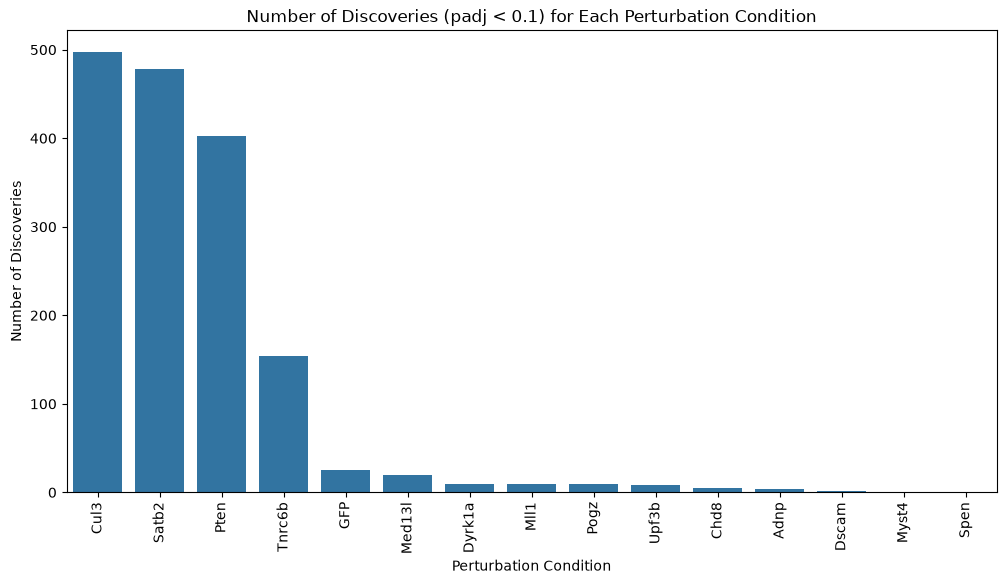

Total significant gene-perturbation pairs (padj < 0.1): 1,626
Perturbation  Count
        Cul3    497
       Satb2    478
        Pten    403
      Tnrc6b    154
         GFP     25
      Med13l     20
      Dyrk1a     10
        Mll1      9
        Pogz      9
       Upf3b      8
        Chd8      5
        Adnp      4
       Dscam      2
       Myst4      1
        Spen      1


,negative_fraction,median_tau,significant,significant_negative,significant_positive
trt,,,,,
Satb2,0.621410,-0.109644,478,356,122
Med13l,0.586815,-0.038543,20,2,18
Upf3b,0.582245,-0.044563,8,7,1
Asxl3,0.580940,-0.022215,0,0,0
Mbd5,0.575065,-0.019569,0,0,0
Scn2a1,0.552219,-0.017866,0,0,0
Setd5,0.528068,-0.010056,0,0,0
Spen,0.483681,0.000000,1,0,1
Ddx3x,0.470627,0.000000,0,0,0


In [40]:
# Filter the results for significant discoveries
significant_discoveries = df_res[df_res['padj'] < 0.1]

# Count the number of discoveries for each perturbation condition
discovery_counts = significant_discoveries['trt'].value_counts().reset_index()
discovery_counts.columns = ['Perturbation', 'Count']

# Plot the number of discoveries for each perturbation condition
plt.figure(figsize=(12, 6))
sns.barplot(data=discovery_counts, x='Perturbation', y='Count')
plt.xticks(rotation=90)
plt.title('Number of Discoveries (padj < 0.1) for Each Perturbation Condition')
plt.xlabel('Perturbation Condition')
plt.ylabel('Number of Discoveries')
plt.show()
print(f"Total significant gene-perturbation pairs (padj < 0.1): {len(significant_discoveries):,}")
print(discovery_counts.to_string(index=False))

direction = df_res.assign(
    significant=df_res['padj'] < 0.1,
    significant_negative=(df_res['padj'] < 0.1) & (df_res['tau'] < 0),
    significant_positive=(df_res['padj'] < 0.1) & (df_res['tau'] > 0),
).groupby('trt').agg(
    negative_fraction=('tau', lambda value: (value < 0).mean()),
    median_tau=('tau', 'median'),
    significant=('significant', 'sum'),
    significant_negative=('significant_negative', 'sum'),
    significant_positive=('significant_positive', 'sum'),
).sort_values('negative_fraction', ascending=False)
display(direction)

### Propensity-score and positivity diagnostics

Positivity requires treated and control cells with comparable covariates. Each perturbation is scored against the shared controls with a five-fold **out-of-fold (OOF)** logistic model using `class_weight='balanced'` — the same model `LFC` uses internally, and *out-of-fold* means each cell is scored by a model that was not trained on it, so an overfit model cannot flatter its own separation. The table reports the histogram overlap between the treated and control scores, the fraction of scores outside `[0.05, 0.95]`, and the **effective sample size (ESS)** of the inverse-probability weights.

ESS is reported as a fraction between 0 and 1: the share of a group's cells that effectively contribute after weighting, so **larger is better** and a small value means a few cells carry the estimate.

Formally, ESS is Kish's effective sample size of the inverse-probability weights:

$$\mathrm{ESS} = \frac{\left(\sum_i w_i\right)^2}{\sum_i w_i^2}, \qquad w_i = \begin{cases} 1/\hat{\pi}_i & \text{treated cells} \\ 1/(1-\hat{\pi}_i) & \text{control cells,} \end{cases}$$

where $\hat{\pi}_i = P(\text{treated} \mid X_i)$ is the propensity score. Equal weights give $\mathrm{ESS}=n$ (fraction 1); a few dominant weights push it toward 0.

The balanced weighting makes the two groups comparable for estimation, so these scores are not literal probabilities of treatment. You would switch to calibrated scores only if you wanted to read a value as P(treated | covariates) — for instance to threshold it or report it directly; then set `class_weight=None` here and `ps_class_weight=None` in `LFC`, and expect better-calibrated but noisier scores.

,treatment,n_treated,overlap_ratio,outside_overlap_fraction,ess_control_fraction,ess_treated_fraction,brier_score
17,Pten,93,0.271,0.208,0.009,0.581,0.105
19,Satb2,51,0.303,0.307,0.467,0.513,0.111
0,GFP,106,0.356,0.075,0.023,0.330,0.129
9,Dyrk1a,89,0.463,0.024,0.039,0.582,0.166
26,Tcf20,93,0.568,0.005,0.170,0.479,0.202
6,Cul3,301,0.577,0.014,0.354,0.730,0.188
16,Pogz,56,0.643,0.001,0.812,0.739,0.217
24,Stard9,151,0.696,0.000,0.834,0.877,0.228


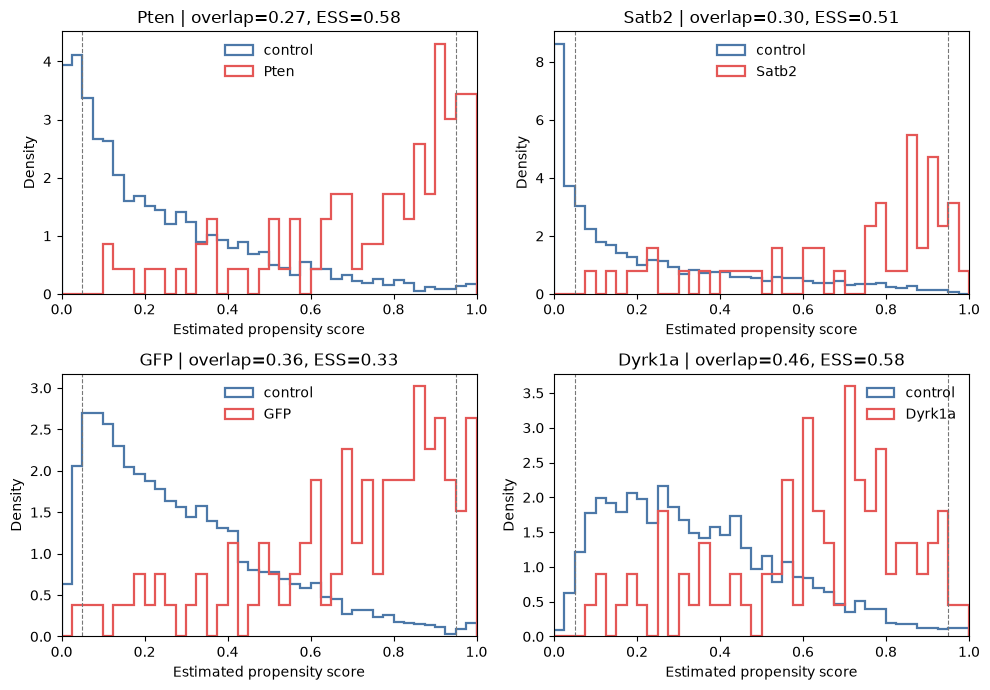

In [41]:
W_A = np.c_[X_A, U]
pi_oof = estimate_propensity_scores(
    A, W_A, K=5, class_weight='balanced', random_state=0,
)
# clip_bounds=None: these are raw out-of-fold scores, nothing has been clipped yet.
ps_summary = summarize_propensity_scores(A, pi_oof, clip_bounds=None)
display(
    ps_summary.sort_values('overlap_ratio')
    [['treatment', 'n_treated', 'overlap_ratio', 'outside_overlap_fraction',
      'ess_control_fraction', 'ess_treated_fraction', 'brier_score']]
    .head(8).round(3)
)

weakest = ps_summary.nsmallest(4, 'overlap_ratio')['treatment'].tolist()
fig, axes, _ = plot_propensity_scores(A, pi_oof, treatments=weakest, clip_bounds=None)
plt.show()

Overfitting shows up as a gap between the in-sample and out-of-fold Brier scores. The next cell computes both, next to a more strongly regularised out-of-fold fit (`C=0.1`), so the table can be read both for overfitting and for whether extra shrinkage actually helps.

In [42]:
pi_train = estimate_propensity_scores(
    A, W_A, K=1, class_weight='balanced', random_state=0,
)
ps_train = summarize_propensity_scores(A, pi_train)
pi_oof_regularized = estimate_propensity_scores(
    A, W_A, K=5, C=0.1, class_weight='balanced', random_state=0,
)
ps_regularized = summarize_propensity_scores(A, pi_oof_regularized)
overfit_check = ps_train[['treatment', 'brier_score']].rename(
    columns={'brier_score': 'brier_train_C1'}
).merge(
    ps_summary[['treatment', 'overlap_ratio', 'brier_score']].rename(
        columns={'brier_score': 'brier_oof_C1'}), on='treatment'
).merge(
    ps_regularized[['treatment', 'overlap_ratio', 'brier_score']].rename(
        columns={'overlap_ratio': 'overlap_ratio_C01', 'brier_score': 'brier_oof_C01'}),
    on='treatment',
)
display(overfit_check.sort_values('overlap_ratio').head(10))

# Reuse fitted outcome models for a propensity sensitivity analysis.
# df_oof, _ = LFC(Y, np.c_[X, U], A, W_A, offset=offsets,
#                 Y_hat=estimation['Y_hat'], pi_hat=pi_oof, usevar='pooled')

,treatment,brier_train_C1,overlap_ratio,brier_oof_C1,overlap_ratio_C01,brier_oof_C01
17,Pten,0.103818,0.270583,0.105287,0.399550,0.144116
19,Satb2,0.110566,0.303150,0.110913,0.398393,0.150530
0,GFP,0.127767,0.355558,0.129011,0.442926,0.161203
9,Dyrk1a,0.164738,0.462979,0.166020,0.545952,0.189850
26,Tcf20,0.200304,0.567690,0.202013,0.657949,0.217531
6,Cul3,0.186702,0.576853,0.188406,0.642332,0.205710
16,Pogz,0.216004,0.643269,0.217051,0.723340,0.226261
24,Stard9,0.226681,0.695889,0.227838,0.722728,0.234428
14,Mll1,0.215754,0.702199,0.216965,0.741381,0.225785
4,Chd8,0.231601,0.716670,0.229809,0.758062,0.234748


**Reading the tables.** A large jump from the in-sample to the out-of-fold Brier score flags overfitting; stronger regularisation (a smaller `C`) is worth adopting only when it lowers the *out-of-fold* Brier, not merely when it makes the histograms overlap more.

The overlap ratio is descriptive, not a hard pass/fail threshold; however, **0.25 is a reasonable rule-of-thumb floor**, and here 28 of the 29 perturbations clear it. Satb2 is the exception: overlap 0.164, 14.0% of its scores outside `[0.05, 0.95]`, and a control ESS of only 0.40. Its estimates deserve more caution than the rest, which makes it the natural candidate for the treatment-specific tuning below.

### Treatment-specific association diagnostics

These helpers apply the same shared-control comparison to observed covariates and latent factors. Spearman correlation captures monotone association, while the standardized mean difference puts it on a familiar effect-size scale. P-values are BH-adjusted across every treatment-by-covariate pair by default; pass `bh_scope='per_treatment'` to adjust within each treatment instead. No cutoff or drop decision is applied for you.

Log-library size is strongly associated with several perturbations, but it is a prespecified technical adjustment and we keep it — association alone is not a reason to drop a covariate, and dropping a genuine confounder to improve an overlap plot trades a visible problem for an invisible one. For Satb2, two latent factors stand out: U9 (Spearman $\rho \approx 0.25$, adjusted $p \approx 0.02$) and U8 ($\rho \approx -0.24$, adjusted $p \approx 0.03$). We use both below in the sensitivity analysis.

,treatment,covariate,covariate_type,n_control,n_treated,spearman_rho,pvalue,padj,standardized_mean_difference,constant,n_tests_in_family
1,GFP,log_library_size,observed,3471,106,0.124411,8.193544e-14,2.703870e-11,0.789328,False,330
73,Cul3,log_library_size,observed,3471,301,0.119505,1.790659e-13,2.954587e-11,0.448267,False,330
205,Pten,log_library_size,observed,3471,93,0.112713,1.498624e-11,1.648486e-09,0.754702,False,330
109,Dyrk1a,log_library_size,observed,3471,89,0.083197,6.664428e-07,5.498153e-05,0.540034,False,330
229,Satb2,log_library_size,observed,3471,51,-0.079656,2.210695e-06,1.459059e-04,-0.732301,False,330
313,Tcf20,log_library_size,observed,3471,93,0.066646,6.840734e-05,3.762404e-03,0.394058,False,330
289,Stard9,log_library_size,observed,3471,151,0.060823,2.496003e-04,1.176687e-02,0.299189,False,330
169,Mll1,log_library_size,observed,3471,117,0.057772,5.357065e-04,2.209789e-02,0.321169,False,330
337,Upf3b,log_library_size,observed,3471,100,-0.047924,4.177361e-03,1.253208e-01,-0.303226,False,330
145,Mbd5,log_library_size,observed,3471,119,-0.042092,1.165990e-02,2.748405e-01,-0.261343,False,330


,treatment,covariate,covariate_type,n_control,n_treated,spearman_rho,pvalue,padj,standardized_mean_difference,constant,n_tests_in_family
238,Satb2,U9,latent,3471,51,0.053824,0.001396,0.051188,0.414212,False,330
239,Satb2,U10,latent,3471,51,-0.039431,0.019275,0.378407,-0.334648,False,330
236,Satb2,U7,latent,3471,51,0.051237,0.002353,0.077650,0.299741,False,330
11,GFP,U10,latent,3471,106,0.045843,0.006102,0.167808,0.261704,False,330
237,Satb2,U8,latent,3471,51,0.026303,0.118598,0.998997,0.220514,False,330
215,Pten,U10,latent,3471,93,0.033537,0.045289,0.622717,0.210592,False,330
166,Med13l,U9,latent,3471,75,-0.029462,0.079401,0.970454,-0.191963,False,330
80,Cul3,U7,latent,3471,301,-0.033843,0.037667,0.557395,-0.179841,False,330
107,Dscam,U10,latent,3471,69,0.027543,0.101321,0.998997,0.175429,False,330
119,Dyrk1a,U10,latent,3471,89,0.033114,0.048197,0.636202,0.172317,False,330


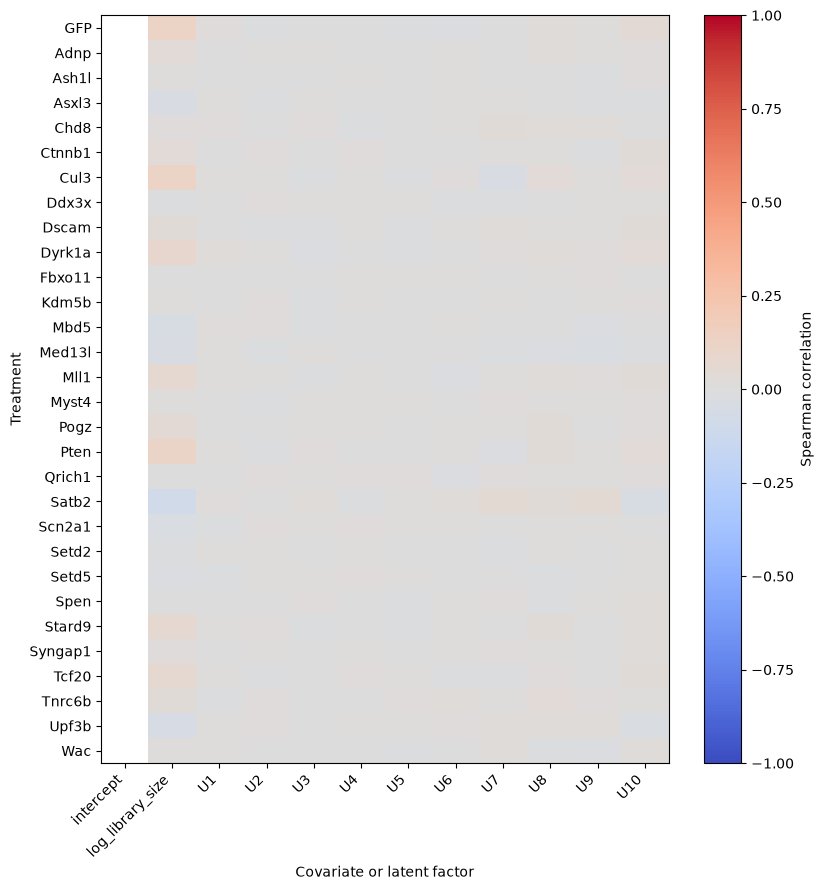

In [43]:
factor_names = [f'U{k + 1}' for k in range(U.shape[1])]
propensity_names = ['intercept', 'log_library_size', *factor_names]
propensity_types = ['observed', 'observed', *(['latent'] * U.shape[1])]
association_summary = summarize_treatment_associations(
    A, W_A, covariate_names=propensity_names,
    covariate_types=propensity_types,
)
observed_associations = association_summary.query("covariate_type == 'observed' and not constant")
latent_associations = association_summary.query("covariate_type == 'latent'").copy()
display(observed_associations.sort_values('padj').head(10))
display(
    latent_associations.assign(abs_smd=lambda frame: frame['standardized_mean_difference'].abs())
    .sort_values('abs_smd', ascending=False).drop(columns='abs_smd').head(10)
)
fig, ax = plot_treatment_associations(association_summary)
plt.show()

#### Tuning Satb2's propensity model

Propensity scores are fit one treatment at a time against the shared controls, so you can change the model for a single perturbation and leave the other 28 untouched. `refit_propensity_scores` refits only the treatments you name and returns an audit table next to the updated scores. Four alternatives for Satb2:

- **drop U9** — remove the single most imbalanced latent factor;
- **drop U8** — remove the other flagged latent factor instead;
- **10x library penalty** — keep every covariate, but apply ten times the usual L2 penalty to standardized log-library size (implemented by dividing that column by $\sqrt{10}$ during both fitting and prediction);
- **Satb2 C=0.1** — keep every covariate and shrink all of them more strongly.

Out-of-fold scores drive the overlap diagnostics; the analysis scores then reuse `estimation['Y_hat']`, so no outcome model is refitted.

,model,n_retained,penalty_factors,degenerate_design,score_std
0,drop U9,11,{},False,0.247
0,drop U8,11,{},False,0.251
0,10x library penalty,12,{'log_library_size': 10.0},False,0.226
0,Satb2 C=0.1,12,{},False,0.192


,model,overlap_ratio,outside_overlap_fraction,ess_control_fraction,ess_treated_fraction,brier_score
19,all factors,0.303,0.307,0.467,0.513,0.111
19,drop U9,0.292,0.309,0.444,0.508,0.111
19,drop U8,0.544,0.080,0.416,0.572,0.198
19,10x library penalty,0.300,0.167,0.708,0.623,0.119
19,Satb2 C=0.1,0.398,0.038,0.880,0.682,0.151


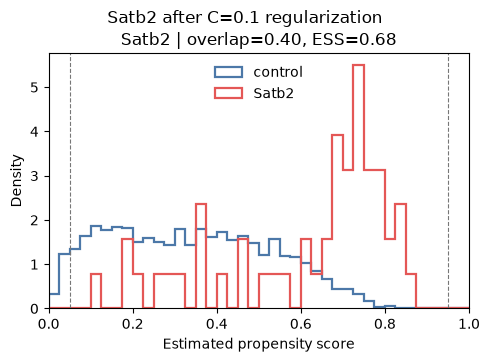

ValueError: operands could not be broadcast together with shapes (8215,4017,1,1) (8215,1532,30,2) 

In [39]:
# Four treatment-specific alternatives for Satb2. Each refits Satb2 alone and
# leaves the other 28 perturbations' scores exactly as they were. The two single-
# factor drops show that *which* flagged factor you remove matters.
satb2_variants = {
    'drop U9': dict(drop_by_treatment={'Satb2': ['U9']}),
    'drop U8': dict(drop_by_treatment={'Satb2': ['U8']}),
    '10x library penalty': dict(
        penalty_factors_by_treatment={'Satb2': {'log_library_size': 10}}),
    'Satb2 C=0.1': dict(drop_by_treatment={'Satb2': []}, C=0.1),
}


def refit_satb2(pi_hat, K, **kwargs):
    return refit_propensity_scores(
        A, W_A, pi_hat=pi_hat, covariate_names=propensity_names, K=K,
        class_weight='balanced', random_state=0, **kwargs,
    )


# Out-of-fold scores, used only for the overlap diagnostics.
oof_variants, audits = {}, []
for name, options in satb2_variants.items():
    scores, audit = refit_satb2(pi_oof, 5, **options)
    oof_variants[name] = scores
    audits.append(audit.assign(model=name))
display(
    pd.concat(audits)
    [['model', 'n_retained', 'penalty_factors', 'degenerate_design', 'score_std']]
    .round(3)
)

satb2_overlap = pd.concat([
    summarize_propensity_scores(A, scores, clip_bounds=None)
    .query("treatment == 'Satb2'").assign(model=name)
    for name, scores in {'all factors': pi_oof, **oof_variants}.items()
])[['model', 'overlap_ratio', 'outside_overlap_fraction',
    'ess_control_fraction', 'ess_treated_fraction', 'brier_score']]
display(satb2_overlap.round(3))

fig, axes, _ = plot_propensity_scores(
    A, oof_variants['Satb2 C=0.1'], treatments=['Satb2'], clip_bounds=None,
)
fig.suptitle('Satb2 after C=0.1 regularization', y=1.02)
plt.show()

# Analysis scores reuse the cached outcome model, so no outcome model is refitted.
satb2_effects = (
    df_res.query("trt == 'Satb2'")[['gene_names', 'tau', 'padj']]
    .rename(columns={'tau': 'tau_all', 'padj': 'padj_all'})
)
comparison = []
for name, options in satb2_variants.items():
    pi_analysis, _ = refit_satb2(estimation['pi_hat_raw'], 1, **options)
    df_alt, _ = LFC(
        Y, np.c_[X, U], A, W_A, offset=offsets, usevar='pooled',
        Y_hat=estimation['Y_hat'], pi_hat=pi_analysis,
    )
    merged = satb2_effects.merge(
        df_alt.query("trt == 'Satb2'")[['gene_names', 'tau', 'padj']], on='gene_names',
    )
    comparison.append({
        'model': name,
        'effect_correlation': merged[['tau_all', 'tau']].corr().iloc[0, 1],
        'median_absolute_change': (merged['tau_all'] - merged['tau']).abs().median(),
        'discoveries': int((merged['padj'] < 0.1).sum()),
    })
display(
    pd.DataFrame(comparison)
    .assign(discoveries_all=int((satb2_effects['padj_all'] < 0.1).sum()))
    .round(3)
)

**What the four variants show.** Which factor you drop matters, and neither single drop is the answer.

Dropping U9 — the single most imbalanced factor — does essentially nothing: overlap barely moves (0.164 to 0.183, still below the 0.25 floor, so it does not fix the problem) and the effects are unchanged (correlation 1.000, 1,852 versus 1,858 discoveries). Dropping U8 instead looks like a win — overlap jumps to 0.306 — but it guts the control effective sample size, from 0.40 to 0.04, and destabilises the effects (correlation 0.84, discoveries 653); a high overlap ratio bought this way is misleading, because the estimate now rests on almost no effective controls. That collapse is a weight problem: dropping U8 pushes a few control cells to propensity scores near 1, so their $1/(1-\hat{\pi}_i)$ weights become extreme and a handful of controls dominate the arm. So the message is *not* "drop U9, keep U8": dropping U9 fixes nothing and dropping U8 does real damage. Factor-dropping is the wrong tool here — keep all the factors and regularise instead.

Penalising the propensity model is reliable. The feature-specific 10x library-size penalty and, more simply, global `C=0.1` both raise overlap into the 0.27–0.29 range — above the 0.25 rule of thumb and in line with the other perturbations — while keeping the effective sample sizes healthy (for `C=0.1`, control 0.63 and treated 0.81) and the effects stable (correlation 0.98). Almost all scores now sit inside `[0.05, 0.95]`. The only real cost is a modest rise in the out-of-fold Brier score, from 0.097 to 0.146 for `C=0.1`.

For a small treatment (51 cells) this is a good trade. A penalised model deliberately accepts a little bias in return for propensity scores that are less variable and better supported, which makes the downstream estimate more trustworthy — exactly the overlapping, in-range scores reviewers ask for. The drop in discoveries (1,858 to 1,568) is not a loss: a conservative, well-supported list is the goal, not the largest one.

In practice, applying `C=0.1` to every perturbation is a sensible default. It gives up a little power on the well-behaved perturbations but spares you from hand-tuning the few problem cases like Satb2 — a good bargain when you have many analyses to run.